<a href="https://colab.research.google.com/github/ZIZOUTOUMOU/LAB02-AdvDB/blob/main/Texture_Classification_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Texture Image Classification: ML vs Deep Learning


## 0 — Environment Setup

In [ ]:
# Install / upgrade libraries
!pip install -q kaggle scikit-image scikit-learn matplotlib seaborn tensorflow

In [ ]:
import os, random, warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Scikit-image & scikit-learn
from skimage import io, color, exposure, filters, transform
from skimage.feature import local_binary_pattern, graycomatrix, graycoprops
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, roc_curve, auc)
from sklearn.pipeline import Pipeline

# TensorFlow / Keras
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print('TensorFlow:', tf.__version__)
print('GPU available:', bool(tf.config.list_physical_devices('GPU')))

TensorFlow: 2.19.0
GPU available: True


## 1 — Dataset Download (Kaggle)

Upload your `kaggle.json` API key when prompted, or paste it manually.

In [ ]:
from google.colab import files
print('Upload your kaggle.json API key:')
uploaded = files.upload()

# Move kaggle.json to the expected location
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
print('kaggle.json configured.')

Upload your kaggle.json API key:


Saving archive.zip to archive.zip
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
kaggle.json configured.


In [ ]:
# --- Download datasets ---
# Describable Textures Dataset (DTD) — 47 classes, ~5600 images
!kaggle datasets download -d tensorflow/tensorflow-datasets --file dtd 2>/dev/null || \
 kaggle datasets download -d jmexpert/describable-textures-dataset-dtd -p data/dtd --unzip

# NEU Surface Defect Database — 6 defect classes
!kaggle datasets download -d kaustubhdikshit/neu-surface-defect-database -p data/neu --unzip

# ---- ALTERNATIVE: use a small built-in demo dataset for quick testing ----
# Uncomment the block below if Kaggle auth isn't set up yet:
# from sklearn.datasets import load_sample_images
# print('Using sklearn sample images for quick demo')

print('Download complete.')

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata
Dataset URL: https://www.kaggle.com/datasets/jmexpert/describable-textures-dataset-dtd
License(s): unknown
100% 1.17G/1.17G [01:14<00:00, 16.8MB/s]

Dataset URL: https://www.kaggle.com/datasets/kaustubhdikshit/neu-surface-defect-database
License(s): unknown
100% 26.4M/26.4M [00:03<00:00, 8.54MB/s]

Download complete.


In [ ]:
# ── Dataset loader ──────────────────────────────────────────────────────────
# NEU-DET structure: data/neu/NEU-DET/train/images/<class_name>/*.jpg
DATA_DIR = Path('data/neu/NEU-DET/train/images')   #  fixed path
IMG_SIZE = (128, 128)
MAX_PER_CLASS = 200

def load_dataset(root: Path, img_size=IMG_SIZE, max_per_class=MAX_PER_CLASS):
    """Walk root/class_name/*.{jpg,png,bmp} and return arrays X, y."""
    X, y = [], []
    class_dirs = sorted([d for d in root.iterdir() if d.is_dir()])
    print(f'Classes found: {[d.name for d in class_dirs]}')
    for cls_dir in class_dirs:
        images = list(cls_dir.glob('*.*'))
        images = [p for p in images if p.suffix.lower() in ('.jpg', '.jpeg', '.png', '.bmp')]
        random.shuffle(images)
        for p in images[:max_per_class]:
            img = io.imread(str(p))
            if img.ndim == 3:
                img = color.rgb2gray(img)
            img = transform.resize(img, img_size, anti_aliasing=True)
            X.append(img)
            y.append(cls_dir.name)
    X = np.array(X, dtype=np.float32)
    le = LabelEncoder()
    y = le.fit_transform(y)
    print(f'Loaded {len(X)} images, {len(le.classes_)} classes.')
    return X, y, le

X_raw, y, label_enc = load_dataset(DATA_DIR)

Classes found: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Loaded 1200 images, 6 classes.


## 2 — Preprocessing

We apply three steps and keep both `X_raw` and `X_proc` to compare their effect later.

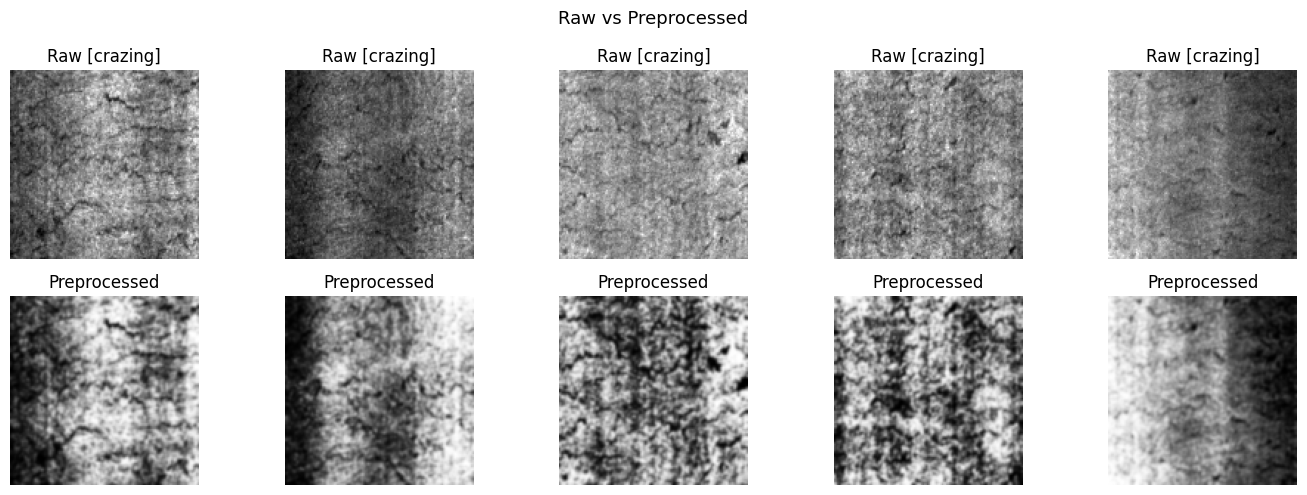

Preprocessing done.


In [ ]:
def preprocess_image(img: np.ndarray) -> np.ndarray:
    """
    1. Histogram equalization  — improves contrast
    2. Gaussian smoothing      — reduces sensor noise
    3. Min-max normalisation   — scales to [0, 1]
    """
    img = exposure.equalize_hist(img)          # histogram equalization
    img = filters.gaussian(img, sigma=0.8)     # spatial smoothing
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)  # normalise
    return img.astype(np.float32)

X_proc = np.array([preprocess_image(img) for img in X_raw])

# ── Visual comparison ───────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 5, figsize=(14, 5))
for i in range(5):
    axes[0, i].imshow(X_raw[i], cmap='gray');  axes[0, i].set_title(f'Raw [{label_enc.classes_[y[i]]}]');  axes[0, i].axis('off')
    axes[1, i].imshow(X_proc[i], cmap='gray'); axes[1, i].set_title('Preprocessed'); axes[1, i].axis('off')
plt.suptitle('Raw vs Preprocessed', fontsize=13)
plt.tight_layout()
plt.show()
print('Preprocessing done.')

## 3 — Stage 1: Baseline — LBP + SVM

Fast to run, interpretable. We test both raw and preprocessed images.

In [ ]:
# ── LBP feature extractor ───────────────────────────────────────────────────
LBP_RADIUS   = 3
LBP_N_POINTS = 8 * LBP_RADIUS
LBP_BINS     = LBP_N_POINTS + 2

def extract_lbp(images: np.ndarray) -> np.ndarray:
    features = []
    for img in images:
        # Convert to uint8 for LBP
        img_u8 = (img * 255).astype(np.uint8)
        lbp = local_binary_pattern(img_u8, LBP_N_POINTS, LBP_RADIUS, method='uniform')
        hist, _ = np.histogram(lbp.ravel(), bins=LBP_BINS, range=(0, LBP_BINS), density=True)
        features.append(hist)
    return np.array(features, dtype=np.float32)

print('Extracting LBP features...')
F_raw  = extract_lbp(X_raw)
F_proc = extract_lbp(X_proc)
print(f'Feature vector shape: {F_raw.shape}')

Extracting LBP features...
Feature vector shape: (1200, 26)


In [ ]:
# ── Also extract GLCM features (optional — adds spatial co-occurrence info) ─
GLCM_DISTANCES  = [1, 3]
GLCM_ANGLES     = [0, np.pi/4, np.pi/2, 3*np.pi/4]
GLCM_PROPERTIES = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation']

def extract_glcm(images: np.ndarray) -> np.ndarray:
    features = []
    for img in images:
        img_u8 = (img * 255).astype(np.uint8)
        glcm = graycomatrix(img_u8, distances=GLCM_DISTANCES, angles=GLCM_ANGLES,
                            levels=256, symmetric=True, normed=True)
        feat = [graycoprops(glcm, prop).ravel() for prop in GLCM_PROPERTIES]
        features.append(np.concatenate(feat))
    return np.array(features, dtype=np.float32)

print('Extracting GLCM features (may take a minute)...')
G_raw  = extract_glcm(X_raw)
G_proc = extract_glcm(X_proc)

# Combine LBP + GLCM
F_combined_raw  = np.hstack([F_raw,  G_raw])
F_combined_proc = np.hstack([F_proc, G_proc])
print(f'Combined feature shape: {F_combined_raw.shape}')

Extracting GLCM features (may take a minute)...
Combined feature shape: (1200, 66)


In [ ]:
# ── Train / test split ──────────────────────────────────────────────────────
def split(F, y, test_size=0.2):
    return train_test_split(F, y, test_size=test_size, random_state=SEED, stratify=y)

Xtr_r, Xte_r, ytr, yte = split(F_combined_raw,  y)
Xtr_p, Xte_p, _,   _   = split(F_combined_proc, y)

# ── SVM with RBF kernel ──────────────────────────────────────────────────────
def train_svm(Xtr, ytr, Xte, yte, label=''):
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(kernel='rbf', C=10, gamma='scale', probability=True, random_state=SEED))
    ])
    pipe.fit(Xtr, ytr)
    acc = accuracy_score(yte, pipe.predict(Xte))
    print(f'SVM {label:20s} accuracy: {acc:.4f}')
    return pipe, acc

svm_raw,  acc_svm_raw  = train_svm(Xtr_r, ytr, Xte_r, yte, label='(raw)')
svm_proc, acc_svm_proc = train_svm(Xtr_p, ytr, Xte_p, yte, label='(preprocessed)')

SVM (raw)                accuracy: 0.9708
SVM (preprocessed)       accuracy: 0.9417


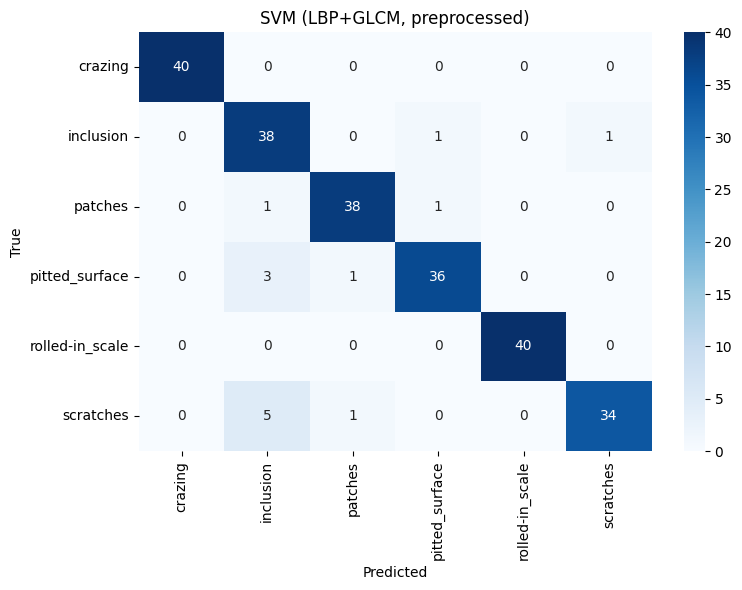

                 precision    recall  f1-score   support

        crazing       1.00      1.00      1.00        40
      inclusion       0.81      0.95      0.87        40
        patches       0.95      0.95      0.95        40
 pitted_surface       0.95      0.90      0.92        40
rolled-in_scale       1.00      1.00      1.00        40
      scratches       0.97      0.85      0.91        40

       accuracy                           0.94       240
      macro avg       0.95      0.94      0.94       240
   weighted avg       0.95      0.94      0.94       240



In [ ]:
# ── Confusion matrix helper ─────────────────────────────────────────────────
def plot_cm(model, Xte, yte, title='Confusion Matrix'):
    preds = model.predict(Xte)
    cm = confusion_matrix(yte, preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_enc.classes_,
                yticklabels=label_enc.classes_)
    plt.title(title); plt.ylabel('True'); plt.xlabel('Predicted')
    plt.tight_layout(); plt.show()
    print(classification_report(yte, preds, target_names=label_enc.classes_))

plot_cm(svm_proc, Xte_p, yte, title='SVM (LBP+GLCM, preprocessed)')

In [ ]:
# ── Also try k-NN and Random Forest for comparison ───────────────────────────
scaler = StandardScaler()
Xtr_s = scaler.fit_transform(Xtr_p)
Xte_s = scaler.transform(Xte_p)

knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn.fit(Xtr_s, ytr)
acc_knn = accuracy_score(yte, knn.predict(Xte_s))

rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
rf.fit(Xtr_s, ytr)
acc_rf = accuracy_score(yte, rf.predict(Xte_s))

print(f'k-NN      accuracy: {acc_knn:.4f}')
print(f'Random Forest acc: {acc_rf:.4f}')

k-NN      accuracy: 0.8750
Random Forest acc: 0.8875


## 4 — Stage 2: ResNet50 Fine-Tuning

We use ResNet50 pre-trained on ImageNet. The top layers are replaced and initially frozen; then we unfreeze the last block for fine-tuning.

In [ ]:
# ── Prepare image arrays for DL ─────────────────────────────────────────────
# ResNet50 expects (224,224,3) RGB uint8 or float32 in [0,1]
DL_IMG_SIZE = (224, 224)

def prepare_dl_images(images_gray: np.ndarray, img_size=DL_IMG_SIZE) -> np.ndarray:
    """Resize grayscale float images → RGB float32 (H,W,3)."""
    out = []
    for img in images_gray:
        img_resized = transform.resize(img, img_size, anti_aliasing=True)
        img_rgb = np.stack([img_resized]*3, axis=-1)  # grey → 3-channel
        out.append(img_rgb)
    return np.array(out, dtype=np.float32)

print('Preparing images for DL (may take a moment)...')
X_dl = prepare_dl_images(X_proc)   # use preprocessed images
print(f'DL image array shape: {X_dl.shape}')

X_tr_dl, X_te_dl, y_tr_dl, y_te_dl = train_test_split(
    X_dl, y, test_size=0.2, random_state=SEED, stratify=y
)
N_CLASSES = len(label_enc.classes_)
print(f'Train: {len(X_tr_dl)}, Test: {len(X_te_dl)}, Classes: {N_CLASSES}')

Preparing images for DL (may take a moment)...
DL image array shape: (1200, 224, 224, 3)
Train: 960, Test: 240, Classes: 6


In [ ]:
# ── Data augmentation (applied only to training data) ───────────────────────
train_datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='reflect'
)

# No augmentation for test set
test_datagen = ImageDataGenerator()

BATCH_SIZE = 32
train_gen = train_datagen.flow(X_tr_dl, tf.keras.utils.to_categorical(y_tr_dl, N_CLASSES), batch_size=BATCH_SIZE, seed=SEED)
test_gen  = test_datagen.flow(X_te_dl,  tf.keras.utils.to_categorical(y_te_dl,  N_CLASSES), batch_size=BATCH_SIZE, shuffle=False)
print('Data generators ready.')

Data generators ready.


In [ ]:
# ── Build ResNet50 model ─────────────────────────────────────────────────────
def build_resnet(n_classes: int, img_size=DL_IMG_SIZE) -> tf.keras.Model:
    base = ResNet50(weights='imagenet', include_top=False,
                   input_shape=(*img_size, 3))
    base.trainable = False  # freeze all at first

    inputs = tf.keras.Input(shape=(*img_size, 3))
    # ResNet50 expects inputs pre-processed with its own scaler
    x = tf.keras.applications.resnet50.preprocess_input(inputs * 255.0)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(n_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model, base

resnet_model, base_model = build_resnet(N_CLASSES)
resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    524,544 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 6)         │      1,542 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,113,798 (91.99 MB)

 Trainable params: 526,086 (2.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
# ── Phase 1: Train top layers only ──────────────────────────────────────────
EPOCHS_PHASE1 = 15
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)
]

history1 = resnet_model.fit(
    train_gen,
    validation_data=test_gen,
    epochs=EPOCHS_PHASE1,
    callbacks=callbacks,
    verbose=1
)
print('Phase 1 complete.')

Epoch 1/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 35s 727ms/step - accuracy: 0.1802 - loss: 2.0147 - val_accuracy: 0.1667 - val_loss: 5.1390 - learning_rate: 0.0010
Epoch 2/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 15s 475ms/step - accuracy: 0.1385 - loss: 1.8471 - val_accuracy: 0.1667 - val_loss: 6.0407 - learning_rate: 0.0010
Epoch 3/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 468ms/step - accuracy: 0.1635 - loss: 1.8019 - val_accuracy: 0.1667 - val_loss: 5.7933 - learning_rate: 0.0010
Epoch 4/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 15s 487ms/step - accuracy: 0.1792 - loss: 1.7900 - val_accuracy: 0.1875 - val_loss: 5.1207 - learning_rate: 0.0010
Epoch 5/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 473ms/step - accuracy: 0.1813 - loss: 1.7817 - val_accuracy: 0.1667 - val_loss: 6.6266 - learning_rate: 0.0010
Epoch 6/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 468ms/step - accuracy: 0.1760 - loss: 1.7760 - val_accuracy: 0.1667 - val_loss: 6.4612 - learning_rate: 0.0010
Epoch 7/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 471ms/step - accuracy: 0.1896 - loss: 1.

In [ ]:
# ── Phase 2: Unfreeze last ResNet block and fine-tune ───────────────────────
# Unfreeze from layer 'conv5_block1_0_conv' onwards
base_model.trainable = True
fine_tune_at = 'conv5_block1_0_conv'
found = False
for layer in base_model.layers:
    if layer.name == fine_tune_at:
        found = True
    layer.trainable = found

trainable = sum(1 for l in base_model.layers if l.trainable)
print(f'Trainable layers after unfreezing: {trainable}')

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),  # lower LR for fine-tuning
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

EPOCHS_PHASE2 = 20
history2 = resnet_model.fit(
    train_gen,
    validation_data=test_gen,
    epochs=EPOCHS_PHASE2,
    callbacks=callbacks,
    verbose=1
)
print('Fine-tuning complete.')

Trainable layers after unfreezing: 26
Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 41s 715ms/step - accuracy: 0.1729 - loss: 3.5809 - val_accuracy: 0.1792 - val_loss: 7.3787 - learning_rate: 1.0000e-05
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 15s 493ms/step - accuracy: 0.1729 - loss: 1.8797 - val_accuracy: 0.1667 - val_loss: 9.0390 - learning_rate: 1.0000e-05
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 15s 495ms/step - accuracy: 0.1677 - loss: 1.8341 - val_accuracy: 0.1708 - val_loss: 10.1031 - learning_rate: 1.0000e-05
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 15s 497ms/step - accuracy: 0.1646 - loss: 1.8067 - val_accuracy: 0.1708 - val_loss: 11.4057 - learning_rate: 5.0000e-06
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 16s 517ms/step - accuracy: 0.2104 - loss: 1.7854 - val_accuracy: 0.1667 - val_loss: 12.5765 - learning_rate: 5.0000e-06
Fine-tuning complete.


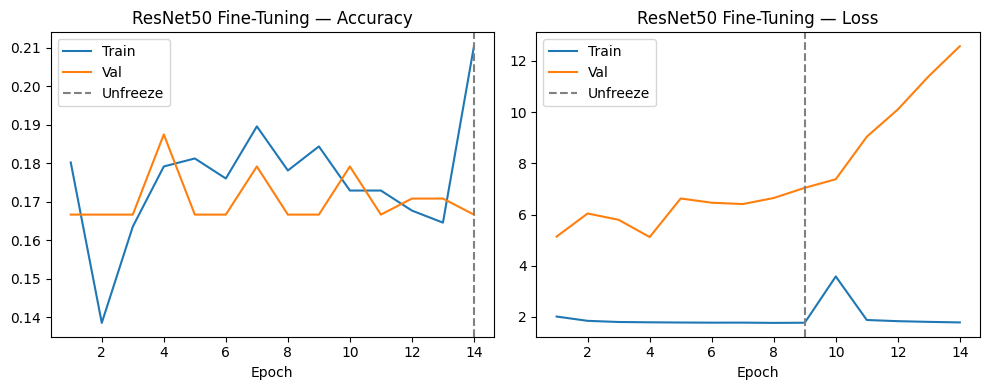

In [ ]:
# ── Plot training curves ─────────────────────────────────────────────────────
def plot_history(h1, h2=None, title='Training history'):
    acc  = h1.history['accuracy']
    val  = h1.history['val_accuracy']
    if h2:
        acc  += h2.history['accuracy']
        val  += h2.history['val_accuracy']
    epochs = range(1, len(acc)+1)
    plt.figure(figsize=(10, 4))
    plt.subplot(1,2,1)
    plt.plot(epochs, acc, label='Train'); plt.plot(epochs, val, label='Val')
    if h2: plt.axvline(len(h1.history['accuracy']), color='gray', linestyle='--', label='Unfreeze')
    plt.legend(); plt.title(title+' — Accuracy'); plt.xlabel('Epoch')
    loss  = h1.history['loss'] + (h2.history['loss'] if h2 else [])
    vloss = h1.history['val_loss'] + (h2.history['val_loss'] if h2 else [])
    plt.subplot(1,2,2)
    plt.plot(epochs, loss, label='Train'); plt.plot(epochs, vloss, label='Val')
    if h2: plt.axvline(len(h1.history['loss']), color='gray', linestyle='--', label='Unfreeze')
    plt.legend(); plt.title(title+' — Loss'); plt.xlabel('Epoch')
    plt.tight_layout(); plt.show()

plot_history(history1, history2, title='ResNet50 Fine-Tuning')

8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 761ms/step
ResNet50 test accuracy: 0.1792


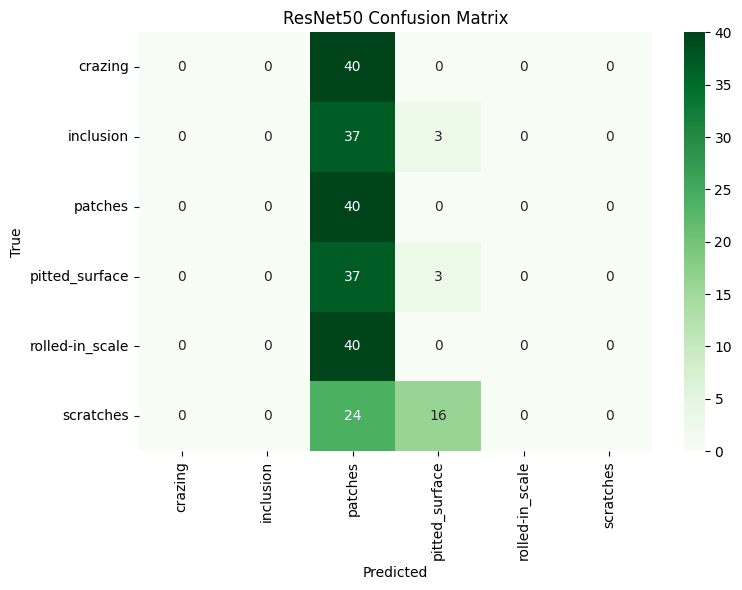

                 precision    recall  f1-score   support

        crazing       0.00      0.00      0.00        40
      inclusion       0.00      0.00      0.00        40
        patches       0.18      1.00      0.31        40
 pitted_surface       0.14      0.07      0.10        40
rolled-in_scale       0.00      0.00      0.00        40
      scratches       0.00      0.00      0.00        40

       accuracy                           0.18       240
      macro avg       0.05      0.18      0.07       240
   weighted avg       0.05      0.18      0.07       240



In [ ]:
# ── Evaluate ResNet ──────────────────────────────────────────────────────────
y_pred_proba = resnet_model.predict(test_gen)
y_pred_dl    = np.argmax(y_pred_proba, axis=1)
acc_resnet   = accuracy_score(y_te_dl, y_pred_dl)
print(f'ResNet50 test accuracy: {acc_resnet:.4f}')

cm_dl = confusion_matrix(y_te_dl, y_pred_dl)
plt.figure(figsize=(8,6))
sns.heatmap(cm_dl, annot=True, fmt='d', cmap='Greens',
            xticklabels=label_enc.classes_, yticklabels=label_enc.classes_)
plt.title('ResNet50 Confusion Matrix'); plt.ylabel('True'); plt.xlabel('Predicted')
plt.tight_layout(); plt.show()
print(classification_report(y_te_dl, y_pred_dl, target_names=label_enc.classes_))

## 5 — Augmentation Experiment

Compare ResNet50 trained **without** augmentation vs **with** augmentation.

In [ ]:
# Build a fresh model with NO augmentation
no_aug_gen = ImageDataGenerator()
no_aug_train = no_aug_gen.flow(X_tr_dl, tf.keras.utils.to_categorical(y_tr_dl, N_CLASSES), batch_size=BATCH_SIZE, seed=SEED)

resnet_noaug, _ = build_resnet(N_CLASSES)
hist_noaug = resnet_noaug.fit(
    no_aug_train,
    validation_data=test_gen,
    epochs=EPOCHS_PHASE1,
    callbacks=callbacks,
    verbose=1
)
y_noaug = np.argmax(resnet_noaug.predict(test_gen), axis=1)
acc_noaug = accuracy_score(y_te_dl, y_noaug)

print(f'ResNet50 WITHOUT augmentation: {acc_noaug:.4f}')
print(f'ResNet50 WITH    augmentation: {acc_resnet:.4f}')
print(f'Augmentation gain: +{(acc_resnet - acc_noaug)*100:.2f}%')

Epoch 1/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 355ms/step - accuracy: 0.8510 - loss: 0.4387 - val_accuracy: 0.9625 - val_loss: 0.1012 - learning_rate: 0.0010
Epoch 2/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 153ms/step - accuracy: 0.9771 - loss: 0.0760 - val_accuracy: 0.9667 - val_loss: 0.0782 - learning_rate: 0.0010
Epoch 3/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 150ms/step - accuracy: 0.9896 - loss: 0.0366 - val_accuracy: 0.9792 - val_loss: 0.0550 - learning_rate: 0.0010
Epoch 4/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 144ms/step - accuracy: 0.9917 - loss: 0.0291 - val_accuracy: 0.9792 - val_loss: 0.0621 - learning_rate: 0.0010
Epoch 5/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 149ms/step - accuracy: 0.9979 - loss: 0.0135 - val_accuracy: 0.9875 - val_loss: 0.0453 - learning_rate: 0.0010
Epoch 6/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 139ms/step - accuracy: 0.9958 - loss: 0.0163 - val_accuracy: 0.9875 - val_loss: 0.0428 - learning_rate: 0.0010
Epoch 7/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 138ms/step - accuracy: 0.9990 - loss: 0.0086 -

## 6 — Evaluation & Final Comparison

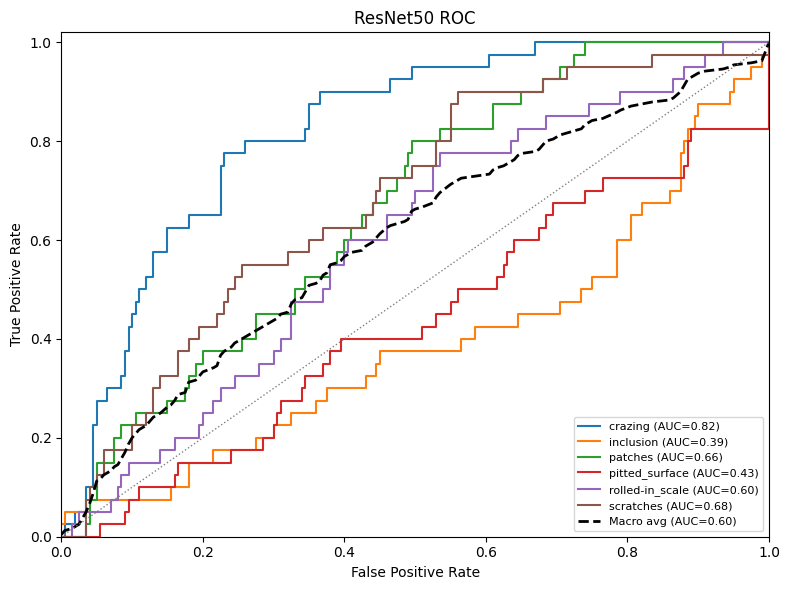

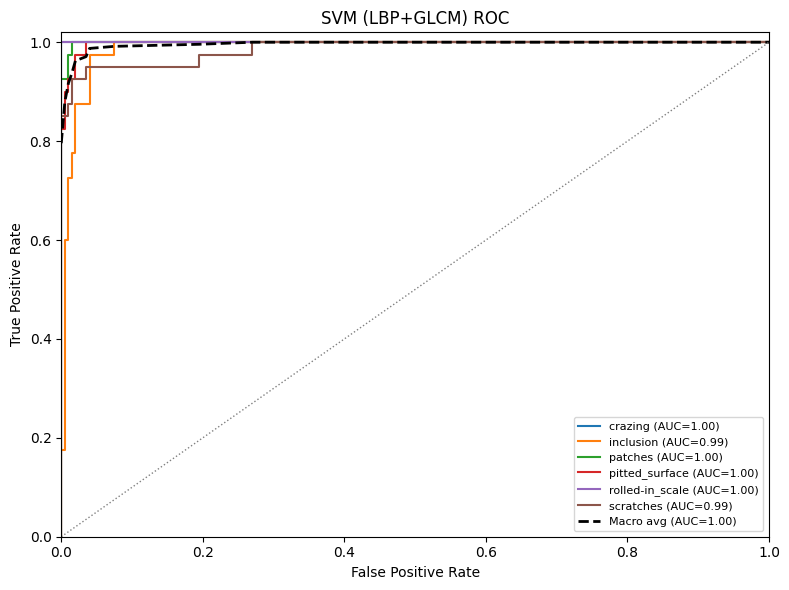

In [ ]:
# ── ROC curves (one-vs-rest, macro-average) ──────────────────────────────────
from sklearn.preprocessing import label_binarize
from itertools import cycle

def plot_roc_multiclass(y_true, y_score, class_names, title='ROC Curves'):
    n_classes = len(class_names)
    Y_bin = label_binarize(y_true, classes=range(n_classes))
    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(Y_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
    # Macro average
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.mean([np.interp(all_fpr, fpr[i], tpr[i]) for i in range(n_classes)], axis=0)
    macro_auc = auc(all_fpr, mean_tpr)

    plt.figure(figsize=(8,6))
    colors = cycle(plt.cm.tab10.colors)
    for i, color in zip(range(n_classes), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=1.5,
                 label=f'{class_names[i]} (AUC={roc_auc[i]:.2f})')
    plt.plot(all_fpr, mean_tpr, 'k--', lw=2, label=f'Macro avg (AUC={macro_auc:.2f})')
    plt.plot([0,1],[0,1],'gray',linestyle=':',lw=1)
    plt.xlim([0,1]); plt.ylim([0,1.02])
    plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
    plt.title(title); plt.legend(loc='lower right', fontsize=8)
    plt.tight_layout(); plt.show()
    return macro_auc

auc_resnet = plot_roc_multiclass(y_te_dl, y_pred_proba, label_enc.classes_, 'ResNet50 ROC')

# SVM probabilities (requires probability=True, already set)
svm_proba = svm_proc.predict_proba(Xte_p)
auc_svm   = plot_roc_multiclass(yte, svm_proba, label_enc.classes_, 'SVM (LBP+GLCM) ROC')


===== Final Results =====
               Model Type Accuracy Macro AUC
   ResNet50 (no aug)   DL   0.9875         -
           SVM (raw)   ML   0.9708  0.996188
  SVM (preprocessed)   ML   0.9417  0.996188
   RF (preprocessed)   ML   0.8875         -
 k-NN (preprocessed)   ML   0.8750         -
ResNet50 (augmented)   DL   0.1792  0.601563


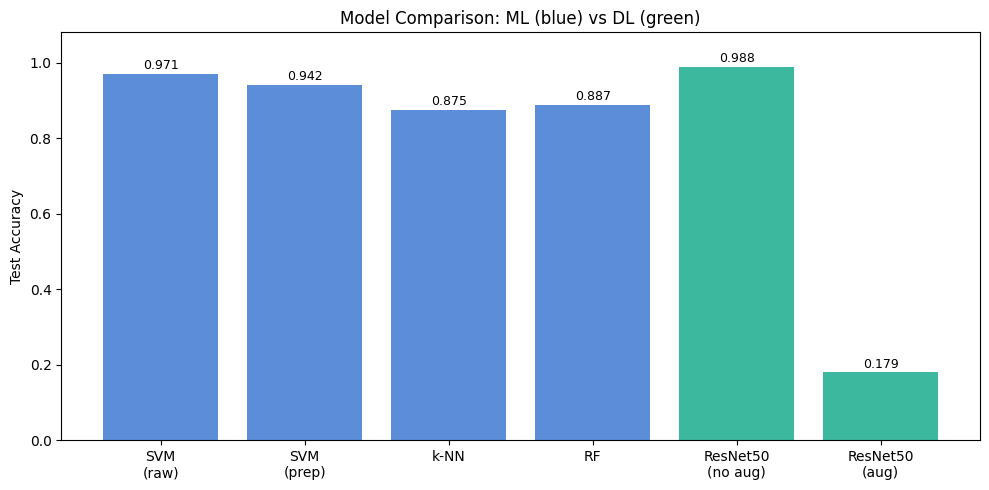

In [ ]:
# ── Final summary table ───────────────────────────────────────────────────────
import pandas as pd

results = pd.DataFrame({
    'Model':       ['SVM (raw)',      'SVM (preprocessed)', 'k-NN (preprocessed)', 'RF (preprocessed)', 'ResNet50 (no aug)', 'ResNet50 (augmented)'],
    'Type':        ['ML','ML','ML','ML','DL','DL'],
    'Accuracy':    [acc_svm_raw, acc_svm_proc, acc_knn, acc_rf, acc_noaug, acc_resnet],
    'Macro AUC':   [auc_svm, auc_svm, '-', '-', '-', auc_resnet]
})

results['Accuracy'] = results['Accuracy'].apply(lambda x: f'{x:.4f}' if isinstance(x, float) else x)
results = results.sort_values('Accuracy', ascending=False)
print('\n===== Final Results =====')
print(results.to_string(index=False))

# Bar chart
accs = [acc_svm_raw, acc_svm_proc, acc_knn, acc_rf, acc_noaug, acc_resnet]
names = ['SVM\n(raw)', 'SVM\n(prep)', 'k-NN', 'RF', 'ResNet50\n(no aug)', 'ResNet50\n(aug)']
colors = ['#5B8DD9','#5B8DD9','#5B8DD9','#5B8DD9','#3BB89E','#3BB89E']

plt.figure(figsize=(10,5))
bars = plt.bar(names, accs, color=colors, edgecolor='none')
for bar, acc in zip(bars, accs):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
             f'{acc:.3f}', ha='center', va='bottom', fontsize=9)
plt.ylim(0, 1.08)
plt.ylabel('Test Accuracy'); plt.title('Model Comparison: ML (blue) vs DL (green)')
plt.tight_layout(); plt.show()

## 7 — Save Models

Download to Drive or local machine.

In [ ]:
import joblib

# Save SVM pipeline
joblib.dump(svm_proc, 'svm_lbp_glcm.pkl')

# Save ResNet50
resnet_model.save('resnet50_texture.keras')

# Optional: save to Google Drive
# from google.colab import drive
# drive.mount('/content/drive')
# !cp svm_lbp_glcm.pkl resnet50_texture.keras /content/drive/MyDrive/

print('Models saved.')

Models saved.


In [ ]:
import joblib

# Save SVM pipeline
joblib.dump(svm_proc, 'svm_lbp_glcm.pkl')

# Save ResNet50
resnet_model.save('resnet50_texture.keras')

# Save to Google Drive (prevents losing files when Colab session ends)
from google.colab import drive
drive.mount('/content/drive')

# Create a folder in your Drive to keep things organized
!mkdir -p /content/drive/MyDrive/texture_classification

# Copy everything there
!cp svm_lbp_glcm.pkl /content/drive/MyDrive/texture_classification/
!cp resnet50_texture.keras /content/drive/MyDrive/texture_classification/

print('Models saved to Google Drive at: MyDrive/texture_classification/')

Mounted at /content/drive
Models saved to Google Drive at: MyDrive/texture_classification/


In [ ]:
# Save the results table too
results.to_csv('/content/drive/MyDrive/texture_classification/results.csv', index=False)
print('Results saved.')

Results saved.


---
## Summary

| Section | What was done |
|---|---|
| Preprocessing | Histogram EQ + Gaussian filter + normalisation |
| Baseline ML | LBP + GLCM → SVM / k-NN / RF, with & without preprocessing |
| Deep Learning | ResNet50 fine-tuned in 2 phases (freeze → unfreeze last block) |
| Augmentation | Classical (rotation, flip, brightness…) — compared with/without |
| Evaluation | Accuracy, confusion matrix, ROC/AUC, final comparison bar chart |

**Next steps:** try DTD (47 classes) for a harder benchmark, experiment with VGG16 or EfficientNetB0, and explore GAN-based augmentation for the most under-represented classes.